<img src="https://drive.google.com/uc?export=view&id=1Q6vQcIWFPY27isBepABpJ7nroUNKox_Z" width="100%">

**Grupo 12**

David Martínez Triana · Andrés Ramírez Romero · David Delgado Ortiz

# Extracción de Características
---

**Proyecto aplicado — Fase 3** (10% del proyecto)

Esta fase elige y construye la representación de las preguntas. El corpus es el de la Fase 2: 839 pares, con el texto original, la pregunta normalizada y la pregunta en lemas.

Cada bloque va en el mismo orden: el código y, debajo, la lectura de lo que imprimió.

La tarea no es clasificar la pregunta. Es dejar un vector con el que la fase 4 pueda comparar una consulta nueva contra las preguntas del corpus.


### **Dónde queda esta fase**

```mermaid
flowchart LR
  IN["CSV limpio<br/>Fase 2"] --> SEL["1. Comparar<br/>5 representaciones"]
  SEL --> IMP["2. Armar matriz<br/>TF-IDF palabras"]
  IMP --> EXP["3. Explorar<br/>IDF, vecinos, empates"]
  EXP --> OUT["Matriz 839 × 1457"]
  OUT --> F4["Fase 4"]
```

No se clasifica la pregunta. Se deja un vector para comparar una consulta nueva con las preguntas del corpus.


In [1]:
from pathlib import Path
import shutil

import pandas as pd

origenes = [
    Path("corpus_faq_unal_fase2_limpio.csv"),
    Path("../Entrega proyecto Fase II/corpus_faq_unal_fase2_limpio.csv"),
]
for origen in origenes:
    if origen.exists():
        destino = Path("corpus_faq_unal_fase2_limpio.csv")
        if origen.resolve() != destino.resolve():
            shutil.copyfile(origen, destino)
        print("Corpus de la Fase 2:", origen.resolve())
        break
else:
    raise FileNotFoundError(
        "No está corpus_faq_unal_fase2_limpio.csv. Súbalo: es el archivo que guarda la Fase 2."
    )

df = pd.read_csv("corpus_faq_unal_fase2_limpio.csv").fillna("")
print(f"Filas: {len(df)} | Columnas: {list(df.columns)}")


Corpus de la Fase 2: C:\Users\J2KUSER\Documents\Diplomado Machine learning Unal 2026\Módulo 4\Módulo 4\Entrega proyecto Fase III\corpus_faq_unal_fase2_limpio.csv
Filas: 839 | Columnas: ['pregunta', 'respuesta', 'fuente', 'url', 'titulo_seccion', 'pregunta_normalizada', 'respuesta_normalizada', 'pregunta_texto_limpio', 'respuesta_texto_limpio']


**Explicación.** La celda trae el archivo limpio de la Fase 2 a esta carpeta. En Colab hay que subir `corpus_faq_unal_fase2_limpio.csv` al directorio de trabajo.

Entran las 839 filas. `pregunta` es el texto original. `pregunta_normalizada` es la que se va a representar. `pregunta_texto_limpio` queda como segunda representación. `fuente`, `url` y `titulo_seccion` no entran al vector: sirven para filtrar y para citar la página.


### **Cómo se eligió la representación**

```mermaid
flowchart TD
  C["Corpus: 839 documentos"] --> R{"Regla del curso"}
  R -->|"menos de 10.000"| BAG["Bolsa / TF-IDF / n-gramas"]
  R -->|"más de 10.000"| W2V["Word2Vec / FastText / Doc2Vec"]
  BAG --> COMP["Misma consulta corta"]
  COMP --> T["TF-IDF palabras<br/>R1 0.912 · 8816 pesos"]
  COMP --> CH["Caracteres 3-5<br/>R1 0.909 · 123240 pesos"]
  COMP --> CT["Conteos / bigramas / lemas"]
  T --> WIN["Se adopta TF-IDF de palabras"]
  CH -.->|"casi empata, cuesta 14 veces"| WIN
```

La cifra 0.912 compara representaciones con una copia acortada de la pregunta oficial. No es la nota de la Fase 4.


## **1. Selección del Embedding**
---

El curso separa las representaciones según el tamaño del corpus y la unidad de texto:

- Bolsas de palabras, TF-IDF y n-gramas de carácter sirven para corpus de menos de 10.000 documentos.
- Word2Vec, FastText y Doc2Vec piden corpus de más de 10.000 documentos para aprender vectores propios.

Este corpus tiene **839 preguntas**. Queda del lado de las bolsas y del TF-IDF. Entrenar aquí un Word2Vec o un FastText aprendería de muy pocos contextos.

La celda siguiente vuelve a medir, sobre este archivo, cinco representaciones con la misma consulta corta de la Fase 2: se quitan las palabras de función y, si quedan más de tres palabras de contenido, se quita la última. La comparación es contra la pregunta, no contra la respuesta. En la Fase 2 esa consulta contra la respuesta quedó en 24.2 %.

Cómo, qué y cuál son muy frecuentes (221, 199 y 134). El IDF les baja el peso dentro de cada pregunta. Los lemas se calculan también, como segunda matriz.


In [2]:
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

PALABRAS_FUNCION = {
    "que", "qué", "como", "cómo", "cual", "cuál", "cuales", "cuáles",
    "donde", "dónde", "cuando", "cuándo", "quien", "quién", "quienes", "quiénes",
    "cuanto", "cuánto", "cuanta", "cuánta", "cuantos", "cuántos",
    "para", "por", "del", "de", "la", "el", "los", "las", "un", "una",
    "es", "son", "se", "me", "mi", "con", "en", "al", "lo", "hay", "y", "o", "a",
    "su", "sus", "le", "les", "te", "nos", "esto", "esta", "este",
}

def consulta_corta(texto):
    tokens = re.findall(r"[a-záéíóúñü0-9]+", str(texto).casefold())
    utiles = [token for token in tokens if token not in PALABRAS_FUNCION and len(token) > 2]
    if len(utiles) > 3:
        utiles = utiles[:-1]
    return " ".join(utiles)

consulta = df["pregunta_normalizada"].map(consulta_corta)
consulta_lemas = df["pregunta_texto_limpio"].map(consulta_corta)
opciones = [
    ("TF-IDF, palabras", TfidfVectorizer(min_df=1, ngram_range=(1, 1)), df["pregunta_normalizada"], consulta),
    ("Conteos, palabras", CountVectorizer(min_df=1, ngram_range=(1, 1)), df["pregunta_normalizada"], consulta),
    ("TF-IDF, palabras y bigramas", TfidfVectorizer(min_df=1, ngram_range=(1, 2)), df["pregunta_normalizada"], consulta),
    ("TF-IDF, caracteres 3 a 5", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1), df["pregunta_normalizada"], consulta),
    ("TF-IDF, lemas", TfidfVectorizer(min_df=1, ngram_range=(1, 1)), df["pregunta_texto_limpio"], consulta_lemas),
]
filas = []
for nombre, vectorizador_local, documentos, consultas in opciones:
    matriz_local = vectorizador_local.fit_transform(documentos)
    similitud = cosine_similarity(vectorizador_local.transform(consultas), matriz_local)
    orden = np.argsort(-similitud, axis=1)
    indice = np.arange(len(consultas))
    recall_1 = float((orden[:, 0] == indice).mean())
    recall_5 = float(np.mean([indice[i] in orden[i, :5] for i in indice]))
    mrr = float(np.mean([1.0 / (int(np.where(orden[i] == i)[0][0]) + 1) for i in indice]))
    filas.append({
        "representación": nombre,
        "términos": int(matriz_local.shape[1]),
        "pesos": int(matriz_local.nnz),
        "Recall@1": round(recall_1, 3),
        "Recall@5": round(recall_5, 3),
        "MRR": round(mrr, 3),
    })
tabla_repr = pd.DataFrame(filas)
display(tabla_repr)


,representación,términos,pesos,Recall@1,Recall@5,MRR
0,"TF-IDF, palabras",1457,8816,0.912,0.998,0.953
1,"Conteos, palabras",1457,8816,0.905,0.998,0.948
2,"TF-IDF, palabras y bigramas",5567,17389,0.902,0.998,0.947
3,"TF-IDF, caracteres 3 a 5",11559,123240,0.909,0.998,0.952
4,"TF-IDF, lemas",1033,5312,0.901,0.996,0.947


**Explicación.** La consulta es una versión corta de la pregunta oficial: se le quitan las palabras de función y la última palabra de contenido. El acierto es si esa consulta recupera su propia fila. Sirve para comparar representaciones entre sí. No es todavía la prueba de la fase 4, porque ahí la consulta la escribe una persona y no sale de recortar la respuesta correcta.

| Representación | Términos | Pesos | Recall@1 | Recall@5 | MRR |
|---|---:|---:|---:|---:|---:|
| TF-IDF, palabras | 1.457 | 8.816 | 0.912 | 0.998 | 0.953 |
| TF-IDF, caracteres de 3 a 5 | 11.559 | 123.240 | 0.909 | 0.998 | 0.952 |
| Conteos, palabras | 1.457 | 8.816 | 0.905 | 0.998 | 0.948 |
| TF-IDF, palabras y bigramas | 5.567 | 17.389 | 0.902 | 0.998 | 0.947 |
| TF-IDF, lemas | 1.033 | 5.312 | 0.901 | 0.996 | 0.947 |

El Recall@5 queda en **0.998** para cuatro representaciones y en **0.996** para los lemas. Con la pregunta recortada, el par oficial casi siempre entra en los cinco primeros. Lo que se decide en esta fase es el primer puesto, y ahí la diferencia cabe en un punto.

El TF-IDF de palabras queda primero y es la matriz más pequeña de las que compiten de cerca. Los caracteres casi empatan (0.909) y guardan **123.240** pesos, catorce veces más que los 8.816 de las palabras. Los bigramas bajan el acierto a 0.902 y triplican el vocabulario. Los conteos, con el mismo vocabulario, quedan en 0.905. Los lemas quedan en 0.901.

La representación de esta fase es el TF-IDF de palabras sueltas sobre `pregunta_normalizada`.


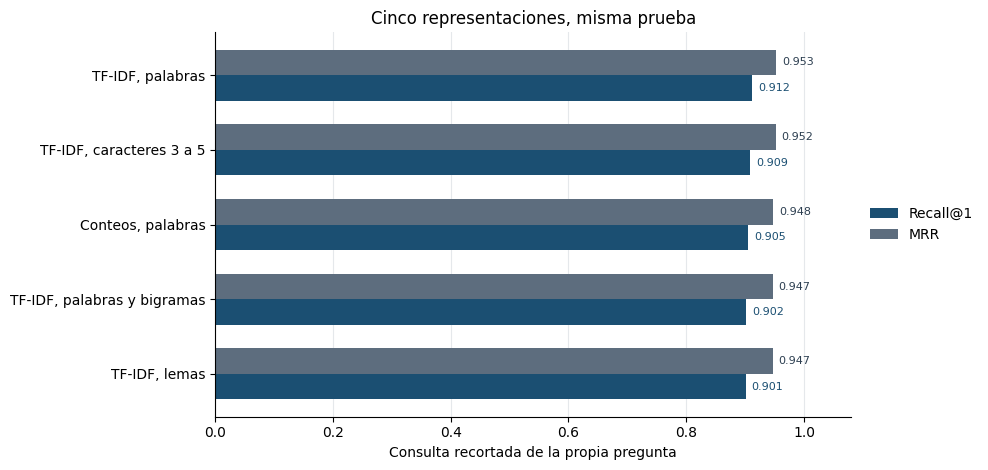

In [3]:
import matplotlib.pyplot as plt

AZUL = "#1b4f72"
GRIS = "#aeb6bf"
ROJO = "#922b21"

orden = tabla_repr.sort_values("Recall@1")
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(orden))
ax.barh(y - 0.17, orden["Recall@1"], height=0.34, color=AZUL, label="Recall@1", zorder=2)
ax.barh(y + 0.17, orden["MRR"], height=0.34, color="#5d6d7e", label="MRR", zorder=2)
ax.set_yticks(y)
ax.set_yticklabels(orden["representación"])
ax.set_xlim(0, 1.08)
ax.set_xlabel("Consulta recortada de la propia pregunta")
ax.set_title("Cinco representaciones, misma prueba")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
for i, (_, fila) in enumerate(orden.iterrows()):
    ax.text(fila["Recall@1"] + 0.01, i - 0.17, f"{fila['Recall@1']:.3f}", va="center", fontsize=8, color=AZUL)
    ax.text(fila["MRR"] + 0.01, i + 0.17, f"{fila['MRR']:.3f}", va="center", fontsize=8, color="#2c3e50")
fig.tight_layout()
plt.show()


**Explicación.** Las cinco barras quedan pegadas al 1. La prueba es fácil a propósito: la consulta sale de la misma pregunta. TF-IDF de palabras queda en Recall@1 **0.912** y MRR **0.953**. Los caracteres quedan a un punto, **0.909** y **0.952**. Conteos, bigramas y lemas siguen entre **0.901** y **0.905**. El gráfico no muestra una ventaja grande. Muestra que, en esta prueba, cambiar de representación mueve poco el primer puesto.


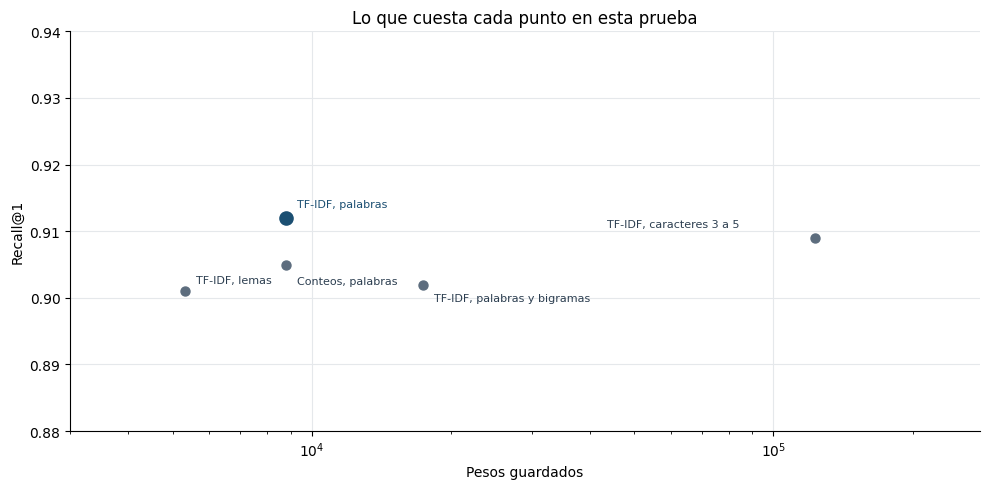

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
desfase = {
    "TF-IDF, palabras": (8, 8),
    "Conteos, palabras": (8, -14),
    "TF-IDF, lemas": (8, 6),
    "TF-IDF, palabras y bigramas": (8, -12),
    "TF-IDF, caracteres 3 a 5": (-150, 8),
}
for _, fila in tabla_repr.iterrows():
    elegido = fila["representación"] == "TF-IDF, palabras"
    ax.scatter(
        fila["pesos"], fila["Recall@1"],
        s=90 if elegido else 42,
        color=AZUL if elegido else "#5d6d7e",
        zorder=3,
    )
    ax.annotate(
        fila["representación"],
        (fila["pesos"], fila["Recall@1"]),
        textcoords="offset points",
        xytext=desfase[fila["representación"]],
        fontsize=8,
        color=AZUL if elegido else "#2c3e50",
    )
ax.set_xscale("log")
ax.set_xlim(3000, 280000)
ax.set_ylim(0.88, 0.94)
ax.set_xlabel("Pesos guardados")
ax.set_ylabel("Recall@1")
ax.set_title("Lo que cuesta cada punto en esta prueba")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


**Explicación.** El eje vertical está abierto entre 0.88 y 0.94 porque las cinco caen ahí: si partiera de cero, los puntos se verían iguales. El eje horizontal es el costo. Palabras y conteos guardan los mismos **8.816** pesos. Los lemas bajan a **5.312** y también bajan el acierto. Los bigramas suben a **17.389**. Los caracteres llegan a **123.240**, unas catorce veces las palabras, para un Recall@1 de **0.909**. La representación que se adopta es la de palabras: queda primera y no paga ese costo.


## **2. Implementación del Embedding**
---

`TfidfVectorizer` de scikit-learn arma las dos matrices en un solo paso, en formato disperso. No se recorre el corpus con un ciclo de Python.


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizador = TfidfVectorizer(min_df=1, ngram_range=(1, 1))
matriz = vectorizador.fit_transform(df["pregunta_normalizada"])

vectorizador_lemas = TfidfVectorizer(min_df=1, ngram_range=(1, 1))
matriz_lemas = vectorizador_lemas.fit_transform(df["pregunta_texto_limpio"])

densidad = matriz.nnz / (matriz.shape[0] * matriz.shape[1])
print(f"Pregunta normalizada: {matriz.shape[0]} preguntas x {matriz.shape[1]} términos.")
print(f"Valores guardados: {matriz.nnz}. Densidad: {densidad:.4%}.")
print(f"Pregunta en lemas: {matriz_lemas.shape[0]} x {matriz_lemas.shape[1]}. Valores guardados: {matriz_lemas.nnz}.")


Pregunta normalizada: 839 preguntas x 1457 términos.
Valores guardados: 8816. Densidad: 0.7212%.
Pregunta en lemas: 839 x 1033. Valores guardados: 5312.


**Explicación.** La matriz principal queda de **839 × 1457**. Solo se guardan **8816** pesos: la densidad es **0.72 %**. Cada pregunta enciende una parte pequeña del vocabulario, así que la fase 4 puede comparar cosenos sin materializar una tabla llena.

La matriz de lemas queda de **839 × 1033**, con **5312** pesos. Es más chica porque los lemas juntan formas de la misma palabra y ya no traen determinantes ni preposiciones. Se conserva para la comparación. La que se usa primero es la de 1457 términos.


## **3. Exploración del Embedding**
---

No hay una etiqueta de clase contra la cual correlacionar el vector. Lo que se revisa es si el peso distingue las palabras de trámite de las palabras que están en casi todas las preguntas, cuántos términos enciende cada pregunta y si una pregunta queda cerca de otras del mismo tema.


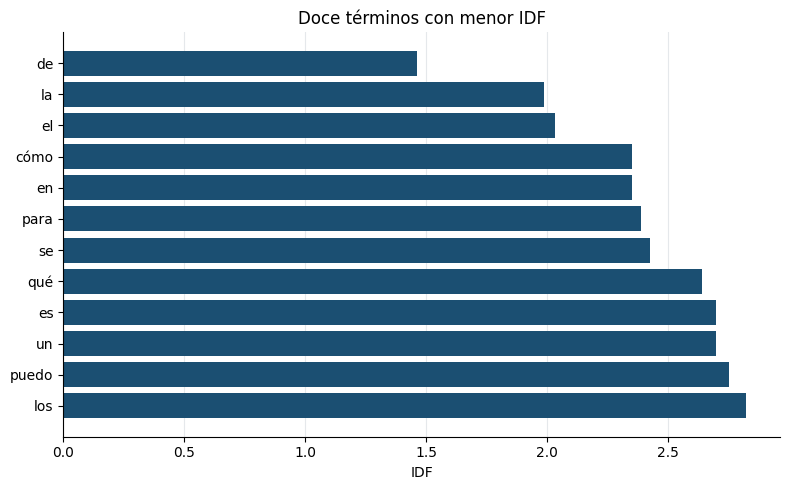

Términos que el IDF más descuenta:
  de               IDF 1.462
  la               IDF 1.987
  el               IDF 2.033
  cómo             IDF 2.349
  en               IDF 2.349
  para             IDF 2.386
  se               IDF 2.425
  qué              IDF 2.640
  es               IDF 2.696
  un               IDF 2.696
  puedo            IDF 2.750
  los              IDF 2.821
Términos que aparecen en una sola pregunta: 723 de 1457. Comparten el IDF máximo 7.040.


In [6]:
idf = vectorizador.idf_
vocabulario = np.array(vectorizador.get_feature_names_out())
menores = np.argsort(idf)[:12]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(vocabulario[menores][::-1], idf[menores][::-1], color=AZUL, zorder=2)
ax.set_title("Doce términos con menor IDF")
ax.set_xlabel("IDF")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

print("Términos que el IDF más descuenta:")
for indice in menores:
    print(f"  {vocabulario[indice]:16} IDF {idf[indice]:.3f}")
frecuencia_doc = np.asarray((matriz > 0).sum(axis=0)).ravel()
en_una = int((frecuencia_doc == 1).sum())
print(f"Términos que aparecen en una sola pregunta: {en_una} de {len(vocabulario)}. Comparten el IDF máximo {idf.max():.3f}.")


**Explicación.** El IDF más bajo es el de las palabras que están en más preguntas: **de** (1.462), **la** (1.987), **el** (2.033), **cómo** (2.349) y **qué** (2.640). Cómo y qué salen en la gráfica de la Fase 2 como las formas más comunes, y aquí quedan entre las que menos pesan. El contenido del trámite —movilidad, semillero, matrícula— no está en esta lista: aparece en pocas preguntas y el IDF lo sube.

De los **1.457** términos, **723** aparecen en una sola pregunta y comparten el IDF máximo **7.040**. No se listan: a ese valor el IDF ya no distingue un término de otro.


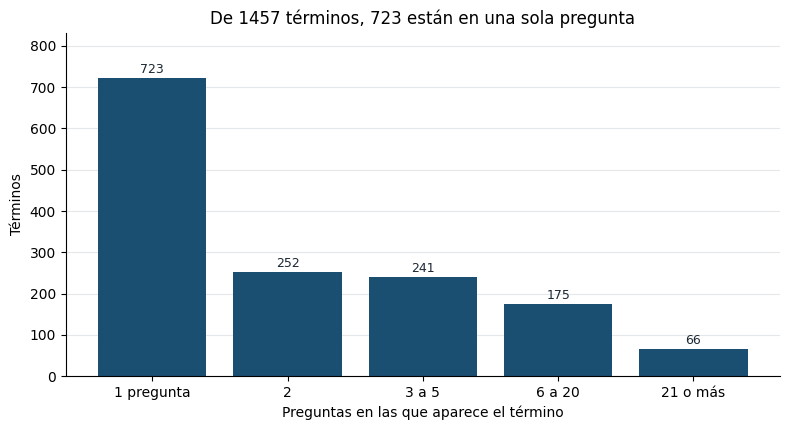

[('1 pregunta', 723), ('2', 252), ('3 a 5', 241), ('6 a 20', 175), ('21 o más', 66)]


In [7]:
cortes = [0, 1, 2, 5, 20, frecuencia_doc.max()]
etiquetas = ["1 pregunta", "2", "3 a 5", "6 a 20", "21 o más"]
conteos_df = [
    int(((frecuencia_doc > cortes[i]) & (frecuencia_doc <= cortes[i + 1])).sum())
    for i in range(5)
]
# el corte (0, 1] con > 0 cuenta los de frecuencia 1; (1, 2] los de 2.
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.bar(etiquetas, conteos_df, color=AZUL, zorder=2)
for i, valor in enumerate(conteos_df):
    ax.text(i, valor + 12, str(valor), ha="center", fontsize=9, color="#1c2833")
ax.set_ylabel("Términos")
ax.set_xlabel("Preguntas en las que aparece el término")
ax.set_title(f"De {len(vocabulario)} términos, {conteos_df[0]} están en una sola pregunta")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
ax.set_ylim(0, max(conteos_df) * 1.15)
fig.tight_layout()
plt.show()
print(list(zip(etiquetas, conteos_df)))


**Explicación.** **723** de los **1.457** términos aparecen en una sola pregunta. Otros **252** aparecen en dos. El IDF máximo, **7.040**, lo comparten todos los de una sola aparición: listarlos no distingue un trámite de otro. Por eso la gráfica de arriba muestra el otro extremo, las palabras que están en muchas preguntas y el peso descuenta. El grueso del vocabulario es raro, y eso es lo que permite que *trámites* o *convocatoria* pesen más que *de*.


In [8]:
from collections import Counter

ganadores = []
matriz_csr = matriz.tocsr()
vocabulario = np.array(vectorizador.get_feature_names_out())
for i in range(matriz_csr.shape[0]):
    fila = matriz_csr.getrow(i)
    if fila.nnz == 0:
        continue
    indice = fila.indices[int(fila.data.argmax())]
    ganadores.append(vocabulario[indice])

conteo = Counter(ganadores)
print("Término de mayor peso dentro de cada pregunta:")
for termino, veces in conteo.most_common(12):
    print(f"  {termino:16} {veces}")


Término de mayor peso dentro de cada pregunta:
  hacer            8
  de               7
  estudios         5
  pierde           5
  las              4
  marco            4
  financiación     4
  cancelación      4
  permiso          4
  período          4
  autónoma         4
  aval             3


**Explicación.** El término que más pesa dentro de cada pregunta no es *de* ni *cómo*. *Hacer* gana en 8 preguntas y *de* en 7. *Las* y *marco* ganan en 4. El resto de ese grupo es el trámite: *estudios*, *pierde*, *financiación*, *cancelación*, *permiso*, *período* y *preparación*, también en 4 o 5. La representación se queda con la acción y el objeto, que es lo que una consulta corta también trae.


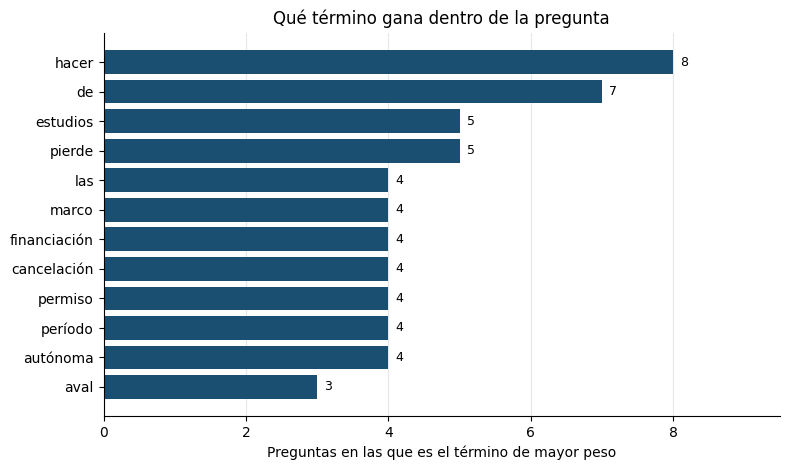

In [9]:
comunes = conteo.most_common(12)
fig, ax = plt.subplots(figsize=(8, 4.8))
nombres = [t for t, _ in comunes][::-1]
veces = [n for _, n in comunes][::-1]
ax.barh(nombres, veces, color=AZUL, zorder=2)
for i, valor in enumerate(veces):
    ax.text(valor + 0.1, i, str(valor), va="center", fontsize=9)
ax.set_xlabel("Preguntas en las que es el término de mayor peso")
ax.set_title("Qué término gana dentro de la pregunta")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
ax.set_xlim(0, max(veces) + 1.5)
fig.tight_layout()
plt.show()


**Explicación.** *Hacer* es el término más pesado en **8** preguntas y *de* en **7**. *Las* y *marco* llegan a **4**, igual que *estudios*, *pierde*, *financiación*, *cancelación*, *permiso*, *período* y *preparación*. La barra deja ver las dos cosas juntas: una palabra de función todavía gana en algunas preguntas cortas, y el resto del grupo es el trámite.


count    839.00
mean      10.51
std        4.55
min        1.00
25%        7.00
50%       10.00
75%       13.00
max       30.00
Name: terminos_activos, dtype: float64


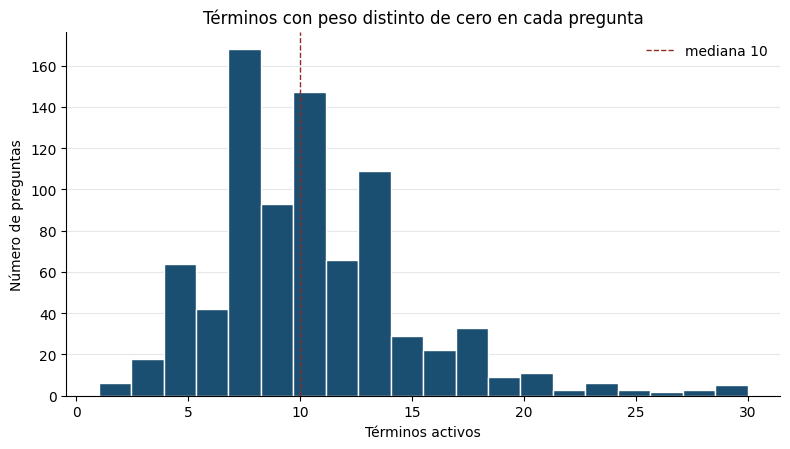

In [10]:
terminos_activos = np.diff(matriz.indptr)
serie = pd.Series(terminos_activos, name="terminos_activos")
print(serie.describe().round(2))

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(terminos_activos, bins=20, color=AZUL, edgecolor="white", zorder=2)
ax.axvline(serie.median(), color=ROJO, linestyle="--", linewidth=1, label=f"mediana {serie.median():.0f}")
ax.set_title("Términos con peso distinto de cero en cada pregunta")
ax.set_xlabel("Términos activos")
ax.set_ylabel("Número de preguntas")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


**Explicación.** Una pregunta enciende en media **10.5** términos (mediana 10, mínimo 1, máximo 30). El histograma se parece al de la longitud en palabras: la mayoría queda entre 7 y 13 términos, y unas pocas preguntas largas llegan a 30. El vector no infla las preguntas cortas ni recorta las de 36 a 41 palabras que se vieron en la Fase 2.


Pregunta de prueba:
¿Qué trámites debo realizar para participar en una convocatoria externa?

Tres preguntas más cercanas en el TF-IDF:
1. coseno 0.547 | Hermes
   ¿Qué necesito para participar en una convocatoria?
2. coseno 0.544 | Hermes
   ¿Cómo hago para solicitar un aval institucional para participar en una convocatoria externa?
3. coseno 0.298 | Ingeniería UECP — Glosario
   Entidad externa

Peso dentro de la pregunta de prueba:
  trámites         0.445
  externa          0.434
  participar       0.382
  convocatoria     0.363
  debo             0.301
  realizar         0.294
  una              0.237
  qué              0.198


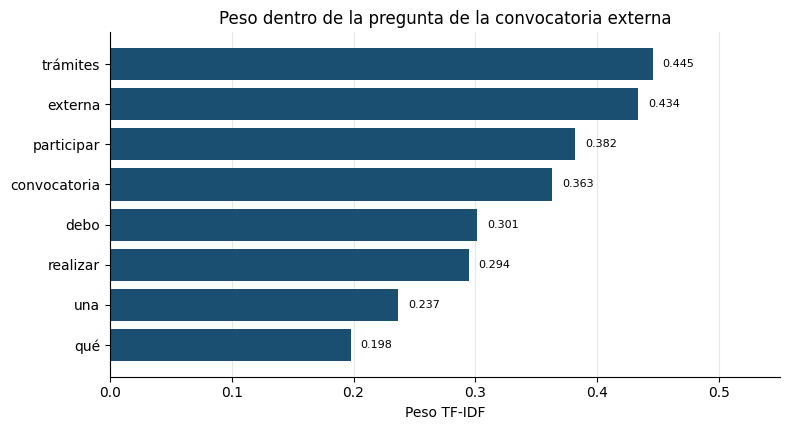

In [11]:
from sklearn.metrics.pairwise import cosine_similarity

fila = df.index[df["pregunta"].str.contains("trámites debo realizar para participar en una convocatoria externa", case=False)][0]
similitud = cosine_similarity(matriz[fila], matriz).ravel()
similitud[fila] = -1
vecinos = np.argsort(-similitud)[:3]

print("Pregunta de prueba:")
print(df.loc[fila, "pregunta"])
print()
print("Tres preguntas más cercanas en el TF-IDF:")
for puesto, indice in enumerate(vecinos, start=1):
    print(f"{puesto}. coseno {similitud[indice]:.3f} | {df.loc[indice, 'fuente']}")
    print(f"   {df.loc[indice, 'pregunta']}")

print()
print("Peso dentro de la pregunta de prueba:")
fila_vector = matriz.getrow(fila)
vocabulario = np.array(vectorizador.get_feature_names_out())
orden_peso = np.argsort(-fila_vector.data)
for peso, termino in list(zip(fila_vector.data[orden_peso], vocabulario[fila_vector.indices[orden_peso]]))[:8]:
    print(f"  {termino:16} {peso:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.4))
terminos_peso = vocabulario[fila_vector.indices[orden_peso]][:8][::-1]
valores_peso = fila_vector.data[orden_peso][:8][::-1]
ax.barh(terminos_peso, valores_peso, color=AZUL, zorder=2)
for i, valor in enumerate(valores_peso):
    ax.text(valor + 0.008, i, f"{valor:.3f}", va="center", fontsize=8)
ax.set_xlim(0, 0.55)
ax.set_xlabel("Peso TF-IDF")
ax.set_title("Peso dentro de la pregunta de la convocatoria externa")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


**Explicación.** La prueba es «¿Qué trámites debo realizar para participar en una convocatoria externa?». Dentro de su vector, lo que más pesa es *trámites* (0.445), *externa* (0.434), *participar* (0.382) y *convocatoria* (0.363). *Qué* queda en 0.198. El IDF ya hizo el trabajo dentro de la pregunta.

Las dos primeras vecinas, con coseno **0.547** y **0.544**, son de Hermes y hablan de participar en una convocatoria y de pedir el aval. La tercera baja a **0.298** y es el término «Entidad externa» del glosario: entra por *externa*, que en esta pregunta pesa 0.434. `fuente` se deja fuera del vector para que la fase 4 pueda apartar el glosario cuando la consulta no lo pide.


El vecino más cercano es de la misma fuente en 56.4% de las preguntas.
El vecino es un término del glosario en 11 preguntas (1.3%).
Preguntas con otra de coseno 1: 107.
Preguntas cuyo vecino queda bajo 0.2: 11.
count    839.000
mean       0.547
std        0.251
min        0.165
25%        0.344
50%        0.470
75%        0.726
max        1.000
Name: coseno_al_vecino, dtype: float64
De esas 107, la cadena normalizada coincide en 99.
En 8 solo cambia una coma, un espacio o un signo de interrogación.

Las 11 preguntas cuyo vecino queda bajo 0.2:


,coseno,fuente,pregunta,fuente_vecina,vecina
3,0.165,Ingeniería Bogotá,¿Cómo verifico que ya está legalizada la contratación?,Ingeniería Bogotá,¿Qué documentos se requieren para llevar a cabo el proceso de contra...
10,0.166,Estadística,¿Qué es la designación de tutor? ¿Cuál es mi profesor tutor asignado?,División salarial,¿CUÁL ES LA FECHA DE PAGO DE LA PRIMA DE SERVICIOS?
7,0.174,DAMA Manizales,¿Cómo me informan que el cupo fue aceptado o negado?,Hermes,¿Cómo puedo saber cuáles fueron los requisitos que no cumplió el pro...
5,0.184,Humanas — Bienestar,¿Dónde se puede y debe presentar un hecho de Violencia Basada en Gén...,Humanas — Bienestar,¿Dónde puedo obtener información sobre Asuntos de Género?
0,0.187,SIAPAL,¿Qué es la versión para impresión?,Estadística,¿Qué es la matrícula de honor? ¿Qué requisitos tiene?
1,0.188,SIAPAL,¿Cómo configuro mi impresora?,Bibliotecas — CLIC,¿Cómo realizo mi inscripción?
4,0.191,Humanas — Bienestar,¿Cómo se presenta un asunto para el conocimiento del CORCAD?,Humanas — Bienestar,¿Cuáles son las funciones del Comité de Resolución de Conflictos y A...
9,0.193,Explora UN Mundo,¿Es necesario comprar algún material educativo como libros o guías?,ORI Medellín,¿Si soy beneficiario de algún programa como renuevo mi beca?
6,0.194,División salarial,¿QUÉ SE ENTIENDE POR AÑO CIVIL?,División salarial,¿CUÁL ES EL PERÍODO DE VACACIONES QUE CORRESPONDE A CADA AÑO DE SERV...
2,0.196,Ingeniería Bogotá,¿quién firma los avales institucionales?,Bibliotecas — índice,¿Quién realiza la publicación de los documentos en el Repositorio In...


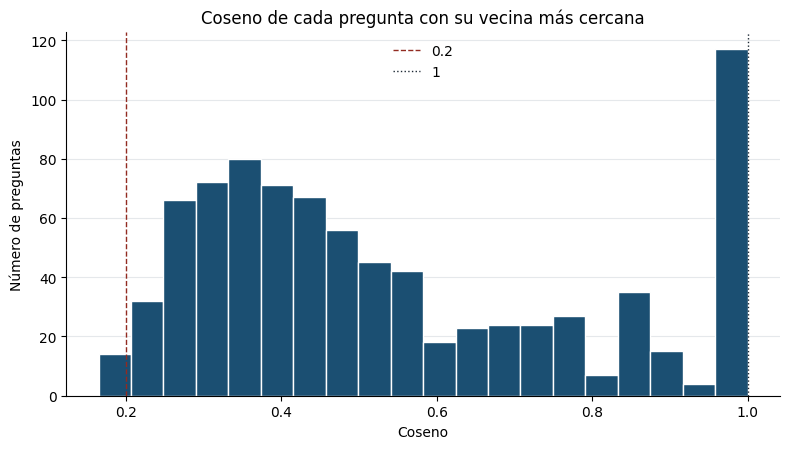

In [12]:
similitud_total = cosine_similarity(matriz)
np.fill_diagonal(similitud_total, -1)
vecino = similitud_total.argmax(axis=1)
coseno_vecino = similitud_total.max(axis=1)
misma_fuente = df.loc[vecino, "fuente"].to_numpy() == df["fuente"].to_numpy()
vecino_glosario = df.loc[vecino, "fuente"].str.contains("Glosario").to_numpy()

print(f"El vecino más cercano es de la misma fuente en {misma_fuente.mean():.1%} de las preguntas.")
print(f"El vecino es un término del glosario en {int(vecino_glosario.sum())} preguntas ({vecino_glosario.mean():.1%}).")
print(f"Preguntas con otra de coseno 1: {int((coseno_vecino >= 0.999).sum())}.")
print(f"Preguntas cuyo vecino queda bajo 0.2: {int((coseno_vecino < 0.2).sum())}.")
print(pd.Series(coseno_vecino, name="coseno_al_vecino").describe().round(3))

iguales = 0
leves = []
for i in np.where(coseno_vecino >= 0.999)[0]:
    propia = str(df.loc[i, "pregunta_normalizada"]).strip()
    ajena = str(df.loc[vecino[i], "pregunta_normalizada"]).strip()
    if propia == ajena:
        iguales += 1
    else:
        leves.append((propia, ajena))
print(f"De esas {int((coseno_vecino >= 0.999).sum())}, la cadena normalizada coincide en {iguales}.")
print(f"En {len(leves)} solo cambia una coma, un espacio o un signo de interrogación.")

debiles = np.where(coseno_vecino < 0.2)[0]
tabla_debil = pd.DataFrame({
    "coseno": np.round(coseno_vecino[debiles], 3),
    "fuente": df.loc[debiles, "fuente"].to_numpy(),
    "pregunta": df.loc[debiles, "pregunta"].to_numpy(),
    "fuente_vecina": df.loc[vecino[debiles], "fuente"].to_numpy(),
    "vecina": df.loc[vecino[debiles], "pregunta"].to_numpy(),
}).sort_values("coseno")
print()
print("Las 11 preguntas cuyo vecino queda bajo 0.2:")
with pd.option_context("display.max_rows", 15, "display.max_colwidth", 72):
    display(tabla_debil)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.hist(coseno_vecino, bins=20, color=AZUL, edgecolor="white", zorder=2)
ax.axvline(0.2, color=ROJO, linestyle="--", linewidth=1, label="0.2")
ax.axvline(1.0, color="#1c2833", linestyle=":", linewidth=1, label="1")
ax.set_title("Coseno de cada pregunta con su vecina más cercana")
ax.set_xlabel("Coseno")
ax.set_ylabel("Número de preguntas")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e5e8eb", zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


**Explicación.** El vecino más cercano es de la misma fuente solo en el **56.4 %** de las preguntas. El otro **43.6 %** cruza de página. Eso conviene: la inscripción a grados y la movilidad están publicadas en Ingeniería y en Estadística, y el vector las puede juntar.

**107** preguntas tienen otra con coseno 1. En **99** la cadena normalizada es la misma. En **8** solo cambia una coma, un espacio o un signo de interrogación. El vector no las separa. La fase 4 tiene que poder mostrar más de un par cuando hay empate.

**11** preguntas (1.3 %) tienen como vecina un término del glosario. Es el mismo efecto de «Entidad externa», a escala del corpus.

La mediana del coseno al vecino es **0.470**. La línea del histograma marca **0.2** y el **1**. **11** preguntas quedan bajo 0.2 y la tabla las lista todas: la impresora de SIAPAL, quién firma los avales, la ruta de violencia de género, el cupo de DAMA, el material de Explora. Un primer puesto con coseno bajo 0.2 no debería presentarse como una respuesta segura.


### **Qué entrega esta fase a la siguiente**

```mermaid
flowchart TD
  M["Matriz TF-IDF<br/>839 × 1457"] --> F4["Fase 4"]
  L["Matriz de lemas<br/>solo como segunda opción"] --> F4
  META["fuente / url / titulo_seccion<br/>fuera del vector"] --> F4
  R1["Coseno 1 = empate<br/>107 preguntas"] --> F4
  R2["Coseno bajo 0.2<br/>11 preguntas"] --> F4
```


### **Qué recibe la fase 4**

- La matriz de **839 × 1457** sobre `pregunta_normalizada`, palabras sueltas, TF-IDF. En la comparación de esta fase quedó en Recall@1 **0.912** y Recall@5 **0.998**, por encima de caracteres (0.909), conteos (0.905), bigramas (0.902) y lemas (0.901). Esa cifra compara representaciones con una consulta recortada de la propia pregunta. El Recall@5 no las separa. La fase 4 tiene que volver a medirla con consultas que no salgan del par correcto.
- La matriz de lemas, **839 × 1033**, solo para repetir la comparación.
- `fuente`, `url` y `titulo_seccion` intactos. El **43.6 %** de las vecinas cruza de fuente, y 11 vecinas son del glosario: la fuente sirve para filtrar, no para entrar al vector.
- Las **107** preguntas con coseno 1 se tratan como empate, no como un único acierto.
- Un vecino con coseno menor que **0.2** se marca como una coincidencia débil. Hay 11 preguntas en ese rango.


## **Créditos**

* **Profesor:** [Felipe Restrepo Calle](https://dis.unal.edu.co/~ferestrepoca/)
* **Asistentes docentes:**
    - [Juan Sebastián Lara Ramírez](https://www.linkedin.com/in/juan-sebastian-lara-ramirez-43570a214/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](mailto:rsuperlano@unal.edu.co).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*
